# Phase 5 — Explore a new text corpus: Airport operations

**Author:** Aboudlal  
**Date:** 2026-10  
**Project:** `nlp-03-text-exploration-custom`

**Analytical question:** How do vocabulary patterns differ among flight operations, staffing, and passenger service descriptions?

This is a **small, invented teaching dataset**. It does **not** represent real airport operations or actual passenger metrics.

We will tokenize and clean text, measure global and category frequencies with **Polars**, examine **co-occurrence** and **bigrams**, and use **matplotlib** to visualize category differences.

In [ ]:
from collections import Counter, defaultdict
import itertools
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


## 1. Create a new labeled corpus

Five short, illustrative documents per category: `flights`, `staffing`, and `passenger_service` (15 total).

In [2]:
corpus = [
    {"category": "flights", "text": "The flight arrives early at the airport."},
    {"category": "flights", "text": "The flight departs after a short delay."},
    {"category": "flights", "text": "Pilots update the flight arrival time."},
    {"category": "flights", "text": "The airport tracks flight schedules and delays."},
    {"category": "flights", "text": "The flight lands near the terminal."},
    {"category": "staffing", "text": "The staff prepare for the morning shift."},
    {"category": "staffing", "text": "Supervisors assign staff to airport positions."},
    {"category": "staffing", "text": "The staffing team checks the shift schedule."},
    {"category": "staffing", "text": "Additional staff support a busy arrival."},
    {"category": "staffing", "text": "The team updates staffing plans for each shift."},
    {
        "category": "passenger_service",
        "text": "Passengers wait at the inspection booth.",
    },
    {
        "category": "passenger_service",
        "text": "The passenger service team answers questions.",
    },
    {
        "category": "passenger_service",
        "text": "Travelers move through the airport queue.",
    },
    {
        "category": "passenger_service",
        "text": "The service desk helps arriving passengers.",
    },
    {
        "category": "passenger_service",
        "text": "Long wait times affect passenger experience.",
    },
]

print(f"Corpus contains {len(corpus)} documents.")
print("Documents per category:")
print(pl.DataFrame(corpus).group_by("category").len().sort("category"))

Corpus contains 15 documents.
Documents per category:
shape: (3, 2)
┌───────────────────┬─────┐
│ category          ┆ len │
│ ---               ┆ --- │
│ str               ┆ u64 │
╞═══════════════════╪═════╡
│ flights           ┆ 5   │
│ passenger_service ┆ 5   │
│ staffing          ┆ 5   │
└───────────────────┴─────┘


## 2. Tokenize and compare frequencies

For frequency tables, omit a small group of common stop words to make topic vocabulary easier to see. For **bigrams and context windows**, preserve the original token order (without stop-word removal).

In [3]:
STOP_WORDS = {"the", "and", "for", "with", "after", "each", "through"}


def tokenize(text: str) -> list[str]:
    """Lowercase text and extract alphabetic tokens of length > 2."""
    return [word for word in re.findall(r"[a-z]+", text.lower()) if len(word) > 2]


records_list = []
for doc in corpus:
    for token in tokenize(doc["text"]):
        if token not in STOP_WORDS:
            records_list.append({"category": doc["category"], "token": token})

token_df = pl.DataFrame(records_list)
global_freq_df = (
    token_df.group_by("token").len().sort(["len", "token"], descending=[True, False])
)
category_freq_df = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len", "token"], descending=[False, True, False])
)

print("Top global token frequencies:")
print(global_freq_df.head(12))
print("\nTop 5 tokens by category:")
for category in ["flights", "staffing", "passenger_service"]:
    print(f"\n{category}:")
    print(category_freq_df.filter(pl.col("category") == category).head(5))

Top global token frequencies:
shape: (12, 2)
┌────────────┬─────┐
│ token      ┆ len │
│ ---        ┆ --- │
│ str        ┆ u64 │
╞════════════╪═════╡
│ flight     ┆ 5   │
│ airport    ┆ 4   │
│ shift      ┆ 3   │
│ staff      ┆ 3   │
│ team       ┆ 3   │
│ …          ┆ …   │
│ passengers ┆ 2   │
│ service    ┆ 2   │
│ staffing   ┆ 2   │
│ wait       ┆ 2   │
│ additional ┆ 1   │
└────────────┴─────┘

Top 5 tokens by category:

flights:
shape: (5, 3)
┌──────────┬─────────┬─────┐
│ category ┆ token   ┆ len │
│ ---      ┆ ---     ┆ --- │
│ str      ┆ str     ┆ u64 │
╞══════════╪═════════╪═════╡
│ flights  ┆ flight  ┆ 5   │
│ flights  ┆ airport ┆ 2   │
│ flights  ┆ arrival ┆ 1   │
│ flights  ┆ arrives ┆ 1   │
│ flights  ┆ delay   ┆ 1   │
└──────────┴─────────┴─────┘

staffing:
shape: (5, 3)
┌──────────┬────────────┬─────┐
│ category ┆ token      ┆ len │
│ ---      ┆ ---        ┆ --- │
│ str      ┆ str        ┆ u64 │
╞══════════╪════════════╪═════╡
│ staffing ┆ shift      ┆ 3   │
│ staffing 

## 3. Co-occurrence and bigram analysis

A context window of **2** examines up to two tokens on either side of a target. Bigrams are adjacent word pairs in the cleaned text **without removing stop words**, so they preserve original adjacency.

In [ ]:
WINDOW_SIZE = 2
TARGET_TOKENS = ["flight", "staff", "passengers"]
co_occurrence_dict = defaultdict(list)
bigrams_list = []

for doc in corpus:
    tokens = tokenize(doc["text"])
    for i, token in enumerate(tokens):
        start = max(0, i - WINDOW_SIZE)
        end = min(len(tokens), i + WINDOW_SIZE + 1)
        for j in range(start, end):
            if j != i:
                co_occurrence_dict[token].append(tokens[j])
    bigrams_list.extend(
        f"{first} {second}" for first, second in itertools.pairwise(tokens)
    )

for target in TARGET_TOKENS:
    print(
        f"Context for '{target}': {Counter(co_occurrence_dict[target]).most_common(6)}"
    )

bigram_df = pl.DataFrame({"bigram": bigrams_list})
bigram_freq_df = (
    bigram_df.group_by("bigram").len().sort(["len", "bigram"], descending=[True, False])
)
print("\nTop bigrams:")
print(bigram_freq_df.head(10))

Context for 'flight': [('the', 4), ('arrives', 1), ('early', 1), ('departs', 1), ('after', 1), ('update', 1)]
Context for 'staff': [('the', 1), ('prepare', 1), ('for', 1), ('supervisors', 1), ('assign', 1), ('airport', 1)]
Context for 'passengers': [('wait', 1), ('the', 1), ('helps', 1), ('arriving', 1)]

Top bigrams:
shape: (10, 2)
┌───────────────────┬─────┐
│ bigram            ┆ len │
│ ---               ┆ --- │
│ str               ┆ u64 │
╞═══════════════════╪═════╡
│ the flight        ┆ 4   │
│ the airport       ┆ 3   │
│ additional staff  ┆ 1   │
│ affect passenger  ┆ 1   │
│ after short       ┆ 1   │
│ airport positions ┆ 1   │
│ airport queue     ┆ 1   │
│ airport tracks    ┆ 1   │
│ and delays        ┆ 1   │
│ answers questions ┆ 1   │
└───────────────────┴─────┘


## 4. Visualize category comparisons

Compare the number of uses of selected words across all three categories. We show zeroes where the word does not appear.

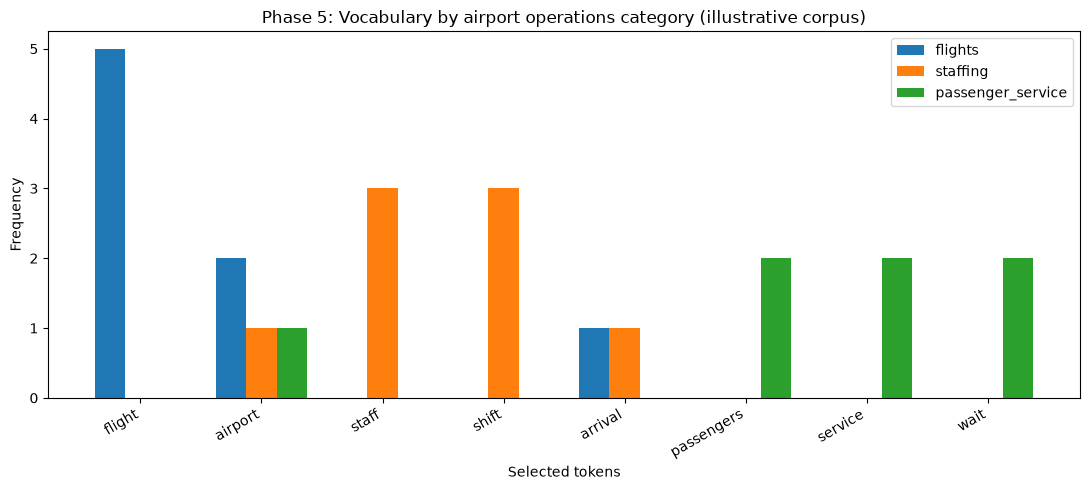

In [5]:
categories = ["flights", "staffing", "passenger_service"]
selected_tokens = [
    "flight",
    "airport",
    "staff",
    "shift",
    "arrival",
    "passengers",
    "service",
    "wait",
]
counts = {
    (row["category"], row["token"]): row["len"]
    for row in category_freq_df.iter_rows(named=True)
}
positions = list(range(len(selected_tokens)))
bar_width = 0.25

plt.figure(figsize=(11, 5))
for i, category in enumerate(categories):
    values = [counts.get((category, token), 0) for token in selected_tokens]
    plt.bar(
        [x + (i - 1) * bar_width for x in positions],
        values,
        width=bar_width,
        label=category,
    )

plt.xticks(positions, selected_tokens, rotation=30, ha="right")
plt.xlabel("Selected tokens")
plt.ylabel("Frequency")
plt.title("Phase 5: Vocabulary by airport operations category (illustrative corpus)")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Interpret the findings and limitations

The vocabulary varies by category: flight descriptions repeatedly mention **flight**; staffing descriptions mention **staff** and **shift**; and passenger-service descriptions mention **passengers**, **service**, and **wait**. The word **airport** can occur in more than one category, so not every token uniquely identifies a topic.

Co-occurrence reveals words appearing near selected terms; bigrams show adjacent pairs. These patterns are useful for **exploration**, but the corpus is deliberately small and invented. **Frequency alone cannot prove word meaning, public sentiment, staffing adequacy, operational performance, or causation.** A real analysis would need authentic data, more documents, and appropriate privacy safeguards.